In [2]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR_HMA_evaluation_paper/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import numpy.ma as ma
from scipy.stats import pearsonr
#import mar

In [3]:
iyr=1981
fyr=2015
domain='GRf'; domainM='GRp'
var='PRE';units='mm/month'

In [4]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/'
#plotsDir='/home/santolam/RECAP/figures/'
plotsDir="//home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/"

In [5]:
model1='MAR'
res1=str('7kmx7km')
nx=ny=10

ds_RF_raw=xr.open_mfdataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domainM}/spin2/work/monthly/'+
                            'RF_monsum_MARv3.14_ER5_spin2_'+domainM+'_*.nc')['RF']
ds_RF = ds_RF_raw.rename({'TIME': 'time'})
units_RF=ds_RF.units
###
ds_SF_raw=xr.open_mfdataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domainM}/spin2/work/monthly/'+
                            'SF_monsum_MARv3.14_ER5_spin2_'+domainM+'_*.nc')['SF']
ds_SF = ds_SF_raw.rename({'TIME': 'time'})
units_SF=ds_SF.units

ds_TF=ds_RF+ds_SF



ds1=ds_TF[:,ny:-ny,nx:-nx].sel(time=slice(str(iyr), str(fyr)))


In [6]:
ds_grid= xr.open_dataset('/home/santolam/NST.2014.01.01.00.GRi.nc')
LONS=ds_grid.LON[ny:-ny,nx:-nx].values
LATS=ds_grid.LAT[ny:-ny,nx:-nx].values
dsSH=ds_grid.SH[ny:-ny,nx:-nx]
dsICE=ds_grid.ICE[ny:-ny,nx:-nx]

In [7]:
print(dsSH.max())

<xarray.DataArray 'SH' ()>
array(5784.88720703)


In [8]:
field1_SH= dsSH.assign_coords({
    'lat': (('y', 'x'), LATS),
    'lon': (('y', 'x'),LONS)
})

In [9]:
field1=ds1.assign_coords({
    'lat': (('Y', 'X'), LATS),
    'lon': (('Y', 'X'),LONS)
})
#field1=field1.rename({"Y":"y","X":"x"})

In [10]:
print(field1_SH.shape,field1.shape)

(62, 96) (420, 62, 96)


In [11]:
###Select the real domain
latS=field1.lat.min(); latN=field1.lat.max()
lonW=field1.lon.min(); lonE=field1.lon.max()


In [12]:
model3='aphro'
res3=str('0.25°x0.25°')

fileName3='APHRO_mon_MA_025deg_V1101_EXR1.1951-2015.nc'
ds3 = xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/aphro/monthly/'
                      +fileName3,decode_times=False)['precip']
start_date = pd.Timestamp('1951-01-01')
# Create new time index
nmonths = ds3.time.size
time_new = pd.date_range(start=start_date, periods=nmonths, freq='MS')  # 'MS' = Month Start
# Replace time in dataset
ds3['time'] = time_new
ds3=dom.reversing_lat(ds3)
ds3=ds3.rename({'latitude':'lat','longitude':'lon'})
field3_mm_day=ds3.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field3_mm_day=field3_mm_day.sel(time=slice(str(iyr),str(fyr)))

# Convert mm/day to mm/month
days_in_month = field3_mm_day['time'].dt.days_in_month
field3= field3_mm_day * days_in_month

field3.shape


(420, 16, 31)

In [13]:
ds3_SH_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+'gmted_on_aphro.nc')['elevation']
ds3_SH=ds3_SH_raw.rename({'latitude':'lat','longitude':'lon'})
ds3_SH=dom.reversing_lat(ds3_SH)
field3_SH=ds3_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field3_SH.shape

(16, 31)

In [14]:
###model 4
model4='gpcp'
res4=str('1.0°x1.0°')

fileName4='precip_mon.gpcp_v2020_1891_2019_10.nc'
ds4= xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/'
                     +model4+'/'+fileName4)['precip']
print(ds4.attrs) 
#ds4=dom.reversing_lat(ds4)
#units in mm/month -> mm/day

field4=ds4.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))

#month_length = field40.time.dt.days_in_month
#
#field4=field40/month_length
field4=field4.sel(time=slice(str(iyr),str(fyr)))
field4.shape


{'long_name': 'gpcc full data monthly product version 2020, precipitation per grid', 'units': 'mm/month', 'code': 20, 'institution': 'DWD'}


(420, 4, 8)

In [15]:
ds4_SH=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+'gmted_on_gpcp.nc')['elevation']
#ds4_SH=ds4_SH.rename({'latitude':'lat','longitude':'lon'})

field4_SH=ds4_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))


In [16]:
print(field4.shape,field4_SH.shape)

(420, 4, 8) (4, 8)


In [17]:
#print(field4.lat[0:2],field3.lat[0:2])

In [18]:
model5='cru'
res5=str('0.5°x0.5°')

fileName5='cru_ts4.05.1901.2020.pre.dat.nc'
ds5_raw= xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/'+model5+'/'+fileName5)['pre']
ds5=dom.reversing_lat(ds5_raw)
field5=ds5.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field5=field5.sel(time=slice(str(iyr),str(fyr)))

In [19]:
#field5

In [20]:
ds5_SH_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/gmted_on_cru_hma_grid.nc')['elevation']
ds5_SH=dom.reversing_lat(ds5_SH_raw)
field5_SH=ds5_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))

In [21]:
model6='chirps'
res6='0.05°x0.05°'
fileName6='chirps-v2.0.monthly.nc'
ds6 = xr.open_dataset(sourceData+model6+'/'+fileName6)['precip']
ds6=ds6.rename({'latitude':'lat','longitude':'lon'})
ds6=dom.reversing_lat(ds6)
field6=ds6.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field6=field6.sel(time=slice(str(iyr),str(fyr)))

print(field6.shape)

(420, 78, 158)


In [22]:
ds6_SH=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+'gmted_on_chirps_hma_grid.nc')['elevation']
ds6_SH=ds6_SH.rename({'latitude':'lat','longitude':'lon'})
ds6_SH=dom.reversing_lat(ds6_SH)
field6_SH=ds6_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field6_SH.shape

(78, 158)

In [23]:
#field5_SH[:,:].plot()

In [24]:
model7='HARv2'
res7='10kmx10km'
#variable='prcp'
fileName7='HARv2_mon_d10km_d_2d_prcp_1980-2023.nc'
ds7_raw0= xr.open_dataset(sourceData+'/'+model7+'/'+fileName7)['prcp']
ds7_raw=ds7_raw0*24 #mm/h
# Calculate days in each month
days_in_month7= ds7_raw['time'].dt.days_in_month
# Convert to mm/month
ds7= ds7_raw* days_in_month7

def xy_sel_dom(ds,latS,latN,lonW,lonE):
    #latS,latN,lonW,lonE,latlim,lonlim=dom.coord_domain(domain)
    lat_str = ''
    lon_str = ''
    other_dims_str = []
    for dim in ds.coords:
        print(dim)
        if dim in ['lat', 'latitude','LON']:
            lat_str = dim
        elif dim in ['lon', 'longitude','LAT']:
            lon_str = dim
        else:
            other_dims_str.append(dim)
    mask = (
        (latS < ds[lat_str]) & ( ds[lat_str] < latN) 
    & (lonW < ds[lon_str]) & ( ds[lon_str] < lonE)
    )
    field_dom=ds.where(mask,drop=True)
    return field_dom

# Apply mask (non-NaN where the condition is True)
#hgt_subset = hgt.where(mask, drop=True)
field7=xy_sel_dom(ds7.sel(time=slice(str(iyr),str(fyr))),latS,latN,lonW,lonE)

time
lon
lat
west_east
south_north


In [25]:
#field7[0,:,:].plot()

In [26]:
fileName7_grF='HARv2_d10km_static_hgt.nc'
ds7_grM= xr.open_dataset(sourceData+'/'+model7+'/'+fileName7_grF)
ds7SH=ds7_grM['hgt'][0,:,:]
#dsSH
field7_SH=xy_sel_dom(ds7SH,latS,latN,lonW,lonE)


time
west_east
south_north
lon
lat


In [27]:
model8='era5'
res8=str('0.25°x0.25°')

#ds8_raw= xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/era5/'
#                         +'tp.mon_era5_1940-2025_NH_025x025.nc')['tp']

ds8_raw= xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/bricej/tp_datasets/tp_HMA_1940-2025_ERA5.nc')['tp']
#ds8=ds8_raw.rename({'valid_time': 'time','latitude':'lat','longitude':'lon'})
ds8=ds8_raw.sel(time=slice(str(iyr),str(fyr)))

field8=ds8.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field8=field8

ds8_SH=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/gmted_on_era5_grid.nc')['elevation']
ds8_SH=ds8_SH.rename({'latitude':'lat','longitude':'lon'})

field8_SH=ds8_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))


In [28]:

## SAME ANALYSIS BUT FOR multiple data sets(at the same time): lists

dsList=[field1,
        field3,field4,field5,field6,
        field7,field8]
modelList=[model1,
           model3,model4,model5,model6,
           model7,model8]
resList=[res1,
         res3,res4,res5,res6,
         res7,res8]
nameList=list(zip(modelList,resList))

In [29]:
nameList

[('MAR', '7kmx7km'),
 ('aphro', '0.25°x0.25°'),
 ('gpcp', '1.0°x1.0°'),
 ('cru', '0.5°x0.5°'),
 ('chirps', '0.05°x0.05°'),
 ('HARv2', '10kmx10km'),
 ('era5', '0.25°x0.25°')]

In [30]:
elevList=[field1_SH,field3_SH,field4_SH,field5_SH,field6_SH,field7_SH,field8_SH]
print(len(elevList))

7


In [31]:
#level_bounds = [(0, 2500), (2500, 4500), (4500, 5500), (5500, 7500)]
#level_bounds = [(5500, 7500),(4500, 5500), (2500, 4500), (0, 2500) ]
level_bounds = [(5500, 7500),(3500, 5500), (1500, 3500), (0, 1500) ]

In [32]:
maskList_field1 = []
for lev_min, lev_max in level_bounds:
    mask = (field1_SH >= lev_min) & (field1_SH < lev_max)
    maskList_field1.append(mask)

maskList_field3 = []
for lev_min, lev_max in level_bounds:
    mask = (field3_SH >= lev_min) & (field3_SH < lev_max)
    maskList_field3.append(mask)

maskList_field4 = []
for lev_min, lev_max in level_bounds:
    mask = (field4_SH >= lev_min) & (field4_SH < lev_max)
    maskList_field4.append(mask)

maskList_field5 = []
for lev_min, lev_max in level_bounds:
    mask = (field5_SH >= lev_min) & (field5_SH < lev_max)
    maskList_field5.append(mask)

maskList_field6 = []
for lev_min, lev_max in level_bounds:
    mask = (field6_SH >= lev_min) & (field6_SH < lev_max)
    maskList_field6.append(mask)

maskList_field7 = []
for lev_min, lev_max in level_bounds:
    mask = (field7_SH >= lev_min) & (field7_SH < lev_max)
    maskList_field7.append(mask)
maskList_field8 = []
for lev_min, lev_max in level_bounds:
    mask = (field8_SH >= lev_min) & (field8_SH < lev_max)
    maskList_field8.append(mask)

In [33]:
field1_season = field1.groupby('time.month').mean('time', skipna=True)
field3_season = field3.groupby('time.month').mean('time', skipna=True)
field4_season = field4.groupby('time.month').mean('time', skipna=True)
field5_season = field5.groupby('time.month').mean('time', skipna=True)
field6_season = field6.groupby('time.month').mean('time', skipna=True)
field7_season = field7.groupby('time.month').mean('time', skipna=True)
field8_season = field8.groupby('time.month').mean('time', skipna=True)

def compute_mean_for_masks(field_season, mask_list, dims):
    mean_vals = []
    for mask in mask_list:
        masked = field_season.where(mask.values)
        for dim in dims:
            masked = masked.mean(dim)
        mean_vals.append(masked)
    return mean_vals

# Then apply it like this:
ac_mean_vals_field1 = compute_mean_for_masks(field1_season, maskList_field1,  ['X', 'Y'])
ac_mean_vals_field3 = compute_mean_for_masks(field3_season, maskList_field3, ['lon', 'lat'])
ac_mean_vals_field4= compute_mean_for_masks(field4_season, maskList_field4,  ['lon', 'lat'])
ac_mean_vals_field5= compute_mean_for_masks(field5_season, maskList_field5,  ['lon', 'lat'])
ac_mean_vals_field6= compute_mean_for_masks(field6_season, maskList_field6,  ['lon', 'lat'])
ac_mean_vals_field7 = compute_mean_for_masks(field7_season, maskList_field7,  ['south_north', 'west_east'])
ac_mean_vals_field8= compute_mean_for_masks(field8_season, maskList_field8,  ['lon', 'lat'])

In [34]:
counts1 = [int(mask.sum()) for mask in maskList_field1]
counts3 = [int(mask.sum()) for mask in maskList_field3]
counts4 = [int(mask.sum()) for mask in maskList_field4]
counts5 = [int(mask.sum()) for mask in maskList_field5]
counts6= [int(mask.sum()) for mask in maskList_field6]
counts7 = [int(mask.sum()) for mask in maskList_field7]
counts8 = [int(mask.sum()) for mask in maskList_field8]

In [35]:
counts1_per = 100 * np.array(counts1) / maskList_field1[0].size
counts3_per = 100 * np.array(counts3) / maskList_field3[0].size
counts4_per = 100 * np.array(counts4) / maskList_field4[0].size
counts5_per = 100 * np.array(counts5) / maskList_field5[0].size
counts6_per = 100 * np.array(counts6) / maskList_field6[0].size
counts7_per = 100 * np.array(counts7) / maskList_field7[0].size
counts8_per = 100 * np.array(counts8) / maskList_field8[0].size


In [36]:

nameListPlot=['MAR (7kmx7km)','APHRO (0.25°x0.25°)', 
              'GPCP (1.0°x1.0°)','CRU (0.5°x0.5°)', 
              'CHRIPS (0.05°x0.05°)','HARv2 (10kmx10km)',
             'ERA5 (0.25°x0.25°)']

In [37]:
colorList=['b','orange', 'pink', 'red', 'green','black','brown']
markerList=['o','X','X','X','X','X','X','X']#

In [38]:
diff_field3 = [ac_mean_vals_field1[i].values - ac_mean_vals_field3[i].values for i in range(4)]
diff_field4 = [ac_mean_vals_field1[i].values - ac_mean_vals_field4[i].values for i in range(4)]
diff_field5 = [ac_mean_vals_field1[i].values - ac_mean_vals_field5[i].values for i in range(4)]
diff_field6 = [ac_mean_vals_field1[i].values - ac_mean_vals_field6[i].values for i in range(4)]
diff_field7 = [ac_mean_vals_field1[i].values - ac_mean_vals_field7[i].values for i in range(4)]
diff_field8 = [ac_mean_vals_field1[i].values - ac_mean_vals_field8[i].values for i in range(4)]


In [39]:
colorList

['b', 'orange', 'pink', 'red', 'green', 'black', 'brown']

/tmp/ipykernel_444671/1476376007.py:115: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.08, 1, 0.95])


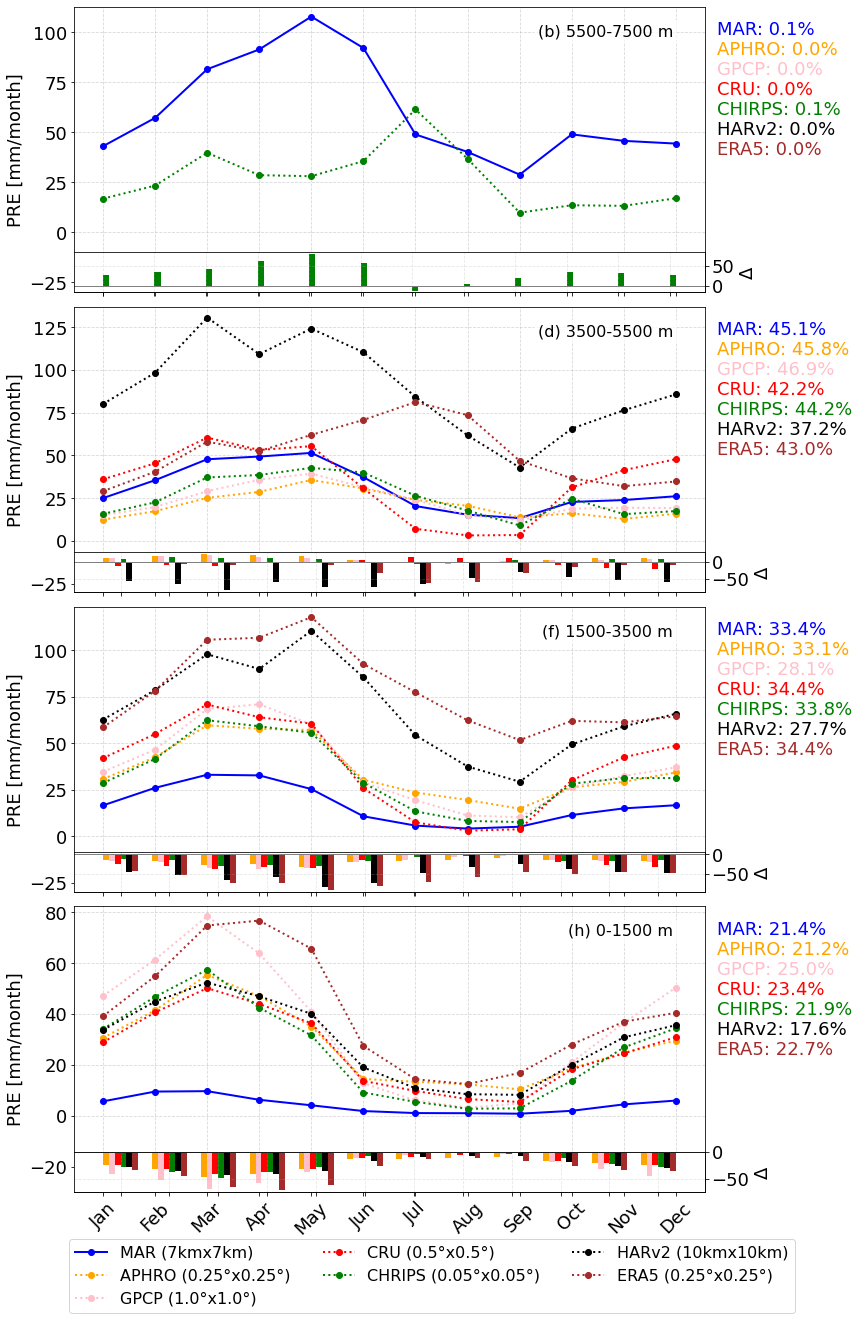

In [41]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

labels_fig=['(b)','(d)','(f)','(h)']
colors = colorList
#elev_labels = ['0-2500', '2500-4500', '4500-5500', '5500-7500']
elev_labels = ['5500-7500','3500-5500','1500-3500','0-1500']

months = np.arange(1, 13)

# --- Crear figura con 4 filas y 1 columna ---
fig, axs = plt.subplots(4, 1, figsize=(12, 20), sharex=True, sharey=False)
plt.subplots_adjust(hspace=0.8)
axs = axs.flatten()

for i, ax in enumerate(axs):
    ax.plot(months, ac_mean_vals_field1[i].values, 'o-', label=nameListPlot[0], color=colors[0], linewidth=2)
    ax.plot(months, ac_mean_vals_field3[i].values, 'o:', label=nameListPlot[1], color=colors[1], linewidth=2)
    ax.plot(months, ac_mean_vals_field4[i].values, 'o:', label=nameListPlot[2], color=colors[2], linewidth=2)
    ax.plot(months, ac_mean_vals_field5[i].values, 'o:', label=nameListPlot[3], color=colors[3], linewidth=2)
    ax.plot(months, ac_mean_vals_field6[i].values, 'o:', label=nameListPlot[4], color=colors[4], linewidth=2)
    ax.plot(months, ac_mean_vals_field7[i].values, 'o:', label=nameListPlot[5], color=colors[5], linewidth=2)
    ax.plot(months, ac_mean_vals_field8[i].values, 'o:', label=nameListPlot[6], color=colors[6], linewidth=2)
    ax.set_ylim(-30)

    #bar_width = 0.14  # slightly narrower to fit 5 bars per month
    #x_offset = [-0.28, -0.14, 0.0, 0.14, 0.28]  # 5 symmetric offsets around each month
    n_bars = 6                       # number of bias datasets
    bar_width = 0.12                 # slightly narrower to avoid overlap
    x_offset = (np.arange(n_bars) - (n_bars - 1) / 2) * bar_width
       # Small inset for bias bars
    ax_inset = inset_axes(ax, width="100%", height="40%", loc='lower right',
                          #bbox_to_anchor=(0, 0., 1, 0.25),
                          bbox_to_anchor=(0, 0., 1, 0.35),  # move further down and taller
                          bbox_transform=ax.transAxes, borderpad=0)

    
    # Plot monthly biases
    ax_inset.bar(months + x_offset[0], diff_field3[i], width=bar_width, color=colors[1],  label='APHRO')
    ax_inset.bar(months + x_offset[1], diff_field4[i], width=bar_width, color=colors[2], label='GPCP')
    ax_inset.bar(months + x_offset[2], diff_field5[i], width=bar_width, color=colors[3], label='CRU')
    ax_inset.bar(months + x_offset[3], diff_field6[i], width=bar_width, color=colors[4], label='CHIRPS')
    ax_inset.bar(months + x_offset[4], diff_field7[i], width=bar_width, color=colors[5],  label='HARv2')
    ax_inset.bar(months + x_offset[5], diff_field8[i], width=bar_width, color=colors[6],  label='ERA5')
    ax_inset.axhline(0, color='grey', lw=1)
    ax_inset.grid(True, linestyle='--', alpha=0.3)

# ---- Right-side y-axis ----
    ax_inset.yaxis.set_label_position("right")
    ax_inset.yaxis.tick_right()
    ax_inset.set_ylabel('Δ', fontsize=18, color='black')
    ax_inset.tick_params(axis='y', labelsize=18, colors='black')

    #ax.set_title(f'Elevation {elev_labels[i]}', fontsize=14)
    ax_inset.set_xticks(months)
    ax_inset.set_xticklabels([])  # hide month names here (keeps top plot clean)

    ax.set_xticks(months)
    ax.set_ylabel(f'{var} [{units}]',fontsize=18)
    #ax.axhline(y=0, color='grey', linestyle='-', linewidth=1)
    ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun',
                        'Jul','Aug','Sep','Oct','Nov','Dec'], rotation=45,fontsize=18)
    ax.tick_params(axis='y', labelsize=18)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.text(
    0.95, 0.94,                      # x, y in axes fraction (0–1)
    f'{labels_fig[i]} {elev_labels[i]} m',   # text string
    transform=ax.transAxes,          # interpret coords relative to axes
    fontsize=16,
    #fontweight='bold',
    va='top', ha='right',
    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')  # optional box
     )
    dy = 0.07  
    xpos = 1.02
    ypos = 0.95

    datasets = [
    ("MAR", counts1_per[i], colorList[0]),
    ("APHRO", counts3_per[i], colorList[1]),
    ("GPCP", counts4_per[i], colorList[2]),
    ("CRU", counts5_per[i], colorList[3]),
    ("CHIRPS", counts6_per[i], colorList[4]),
    ("HARv2", counts7_per[i], colorList[5]),
    ("ERA5", counts8_per[i], colorList[6]),
    ]

    for j, (name, count, color) in enumerate(datasets):
        ax.text(
        xpos, ypos - j * dy,
        f"{name}: {count:.1f}%",
        color=color,
        transform=ax.transAxes,
        fontsize=18,
        va='top', ha='left',
        bbox=dict(facecolor='white', alpha=0.0, edgecolor='none')  # transparent background for each line
    )    #ax.set_aspect(0.5)

    #ax.set_aspect(1)
# Título general
#

# Leyenda común abajo
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.03),
    ncol=3,
    fontsize=16,
    frameon=True
)

# Ajustar espacio para la leyenda
plt.tight_layout(rect=[0, 0.08, 1, 0.95])
#lt.suptitle(f'Annual cycle {domain} ({iyr}-{fyr})',fontsize=18,y=0.95,x=0.55)


#plotname=f'FIG4_annual_cycle_by_elev_pre_pamir_different_elev_era5_{iyr}-{fyr}_rev1_per'
#fig.suptitle(plotname, fontsize=16)
#plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight")
#print(f"Saved: {plotsDir}{plotname}.png")

plt.show()


In [42]:
print(model3,elev_labels[0],diff_field3[0])
print(model3,elev_labels[1],diff_field3[1])
print(model3,elev_labels[2],diff_field3[2])
print(model3,elev_labels[3],diff_field3[3])

print(model4,elev_labels[0],diff_field4[0])
print(model4,elev_labels[1],diff_field4[1])
print(model4,elev_labels[2],diff_field4[2])
print(model4,elev_labels[3],diff_field4[3])

aphro 5500-7500 [nan nan nan nan nan nan nan nan nan nan nan nan]
aphro 3500-5500 [12.59561698 18.10156974 22.60131484 20.66838348 15.79837754  6.65631992
 -3.57324795 -5.23239007 -0.47821519  6.65285458 11.04077459 10.19798844]
aphro 1500-3500 [-14.1444464  -16.49014554 -26.63024288 -25.05729989 -31.76683329
 -19.67517988 -17.79028906 -15.38870093  -9.68914401 -14.92204164
 -14.25046948 -17.63966513]
aphro 0-1500 [-24.98191569 -31.98068905 -45.72441131 -40.72251851 -30.97895307
 -12.63577076 -12.32907757 -11.33023014  -9.57119581 -16.71689547
 -20.27142319 -23.58790576]
gpcp 5500-7500 [nan nan nan nan nan nan nan nan nan nan nan nan]
gpcp 3500-5500 [ 9.930153   15.717375   18.63809    13.575142   12.069496    5.977577
 -3.650999    0.20886326  1.1964788   3.9275036   4.5189304   6.899399  ]
gpcp 1500-3500 [-18.02955   -20.556675  -35.31787   -38.26617   -34.726414  -18.28301
 -13.632519   -7.0469265  -5.103498  -14.998327  -17.409786  -20.316755 ]
gpcp 0-1500 [-41.484116  -51.907936  

In [43]:
print(model5,elev_labels[0],diff_field5[0])
print(model5,elev_labels[1],diff_field5[1])
print(model5,elev_labels[2],diff_field5[2])
print(model5,elev_labels[3],diff_field5[3])

print(model6,elev_labels[0],diff_field6[0])
print(model6,elev_labels[1],diff_field6[1])
print(model6,elev_labels[2],diff_field6[2])
print(model6,elev_labels[3],diff_field6[3])

print(model7,elev_labels[0],diff_field7[0])
print(model7,elev_labels[1],diff_field7[1])
print(model7,elev_labels[2],diff_field7[2])
print(model7,elev_labels[3],diff_field7[3])

cru 5500-7500 [nan nan nan nan nan nan nan nan nan nan nan nan]
cru 3500-5500 [-10.9917755  -9.905884  -12.666672   -3.8256912  -3.939907    6.554899
  13.284945   12.114932    9.8865185  -8.45961   -17.473597  -21.707382 ]
cru 1500-3500 [-25.390608  -28.943935  -37.7978    -31.266796  -35.249264  -15.075676
  -1.7091289   1.1202972   1.365653  -18.702864  -27.494068  -32.004135 ]
cru 0-1500 [-23.235012  -31.13765   -40.525837  -37.70085   -32.27099   -11.850746
  -8.695301   -5.5535126  -4.608156  -16.369371  -20.059032  -24.928635 ]
chirps 5500-7500 [ 26.21755   33.84745   41.74988   62.865505  79.800224  56.59074
 -12.485401   3.466652  19.035683  35.441586  32.497253  27.332676]
chirps 3500-5500 [ 9.186979  12.939877  10.645218  10.79496    8.707626  -2.7019577
 -6.0126286 -2.4210215  4.259444  -1.9089794  8.248462   8.686323 ]
chirps 1500-3500 [-11.98909   -15.549896  -29.338787  -26.41053   -30.29166   -18.035025
  -7.6366324  -4.119794   -2.5217056 -16.845991  -16.312496  -14.58

In [44]:
print(model8,elev_labels[0],diff_field8[0])
print(model8,elev_labels[1],diff_field8[1])
print(model8,elev_labels[2],diff_field8[2])
print(model8,elev_labels[3],diff_field8[3])

era5 5500-7500 [nan nan nan nan nan nan nan nan nan nan nan nan]
era5 3500-5500 [ -4.04916153  -4.95909975 -10.26907377  -3.11163421 -10.5474738
 -33.47204274 -60.80337109 -58.21257344 -33.50476133 -13.81583029
  -8.12655071  -8.62560083]
era5 1500-3500 [-41.91194927 -52.16083205 -72.60118846 -74.0158837  -92.44817691
 -81.91365745 -71.66496219 -58.20755219 -46.5958731  -50.65173371
 -46.26830861 -47.81155324]
era5 0-1500 [-33.48799423 -45.37777182 -65.15069921 -70.50267118 -61.64453461
 -25.62116011 -13.27987527 -11.47372131 -16.0391932  -26.08390207
 -32.51709413 -34.52706278]
